# Campaign Response Analysis

This notebook compares marketing campaign response rates across the final customer clusters.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../marketing_campaign_clustered.csv")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Children,TotalSpending,TotalPurchases,Age,Cluster
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,3,11,1,0,1617,22,57,3
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,3,11,0,2,27,4,60,1
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,3,11,0,0,776,20,49,2
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,3,11,0,1,53,6,30,5
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,3,11,0,1,422,14,33,4


## 1. Campaign Variables

The campaign variables indicate whether a customer accepted each marketing campaign. The response rates are compared across the identified customer clusters.

In [2]:
campaign_cols = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

df[campaign_cols].head()

,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response
0,0,0,0,0,0,1
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,0,0,0,0
4,0,0,0,0,0,0


### Checking Campaign Variables

The campaign variables should be binary, where 1 indicates that the customer accepted the campaign and 0 indicates that they did not.

In [3]:
for col in campaign_cols:
    print(col, df[col].unique())

AcceptedCmp1 [0 1]
AcceptedCmp2 [0 1]
AcceptedCmp3 [0 1]
AcceptedCmp4 [0 1]
AcceptedCmp5 [0 1]
Response [1 0]


## 2. Campaign Response Rates by Cluster

Since the campaign variables are binary, their mean within each cluster represents the proportion of customers who accepted each campaign.

In [4]:
response_rates = df.groupby("Cluster")[campaign_cols].mean()

response_rates

,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response
Cluster,,,,,,
0,0.255556,0.037037,0.125926,0.140741,0.333333,0.340741
1,0.008130,0.005420,0.054201,0.037940,0.000000,0.062331
2,0.070081,0.018868,0.067385,0.118598,0.061995,0.199461
3,0.107612,0.028871,0.049869,0.157480,0.125984,0.131234
4,0.002618,0.000000,0.060209,0.007853,0.000000,0.052356
5,0.004556,0.000000,0.095672,0.011390,0.000000,0.168565


In [5]:
response_rates_pct = response_rates * 100

response_rates_pct.round(1)

,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response
Cluster,,,,,,
0,25.6,3.7,12.6,14.1,33.3,34.1
1,0.8,0.5,5.4,3.8,0.0,6.2
2,7.0,1.9,6.7,11.9,6.2,19.9
3,10.8,2.9,5.0,15.7,12.6,13.1
4,0.3,0.0,6.0,0.8,0.0,5.2
5,0.5,0.0,9.6,1.1,0.0,16.9


## Campaign Response Comparison

The campaign acceptance rates are visualized to compare response patterns across the customer clusters.

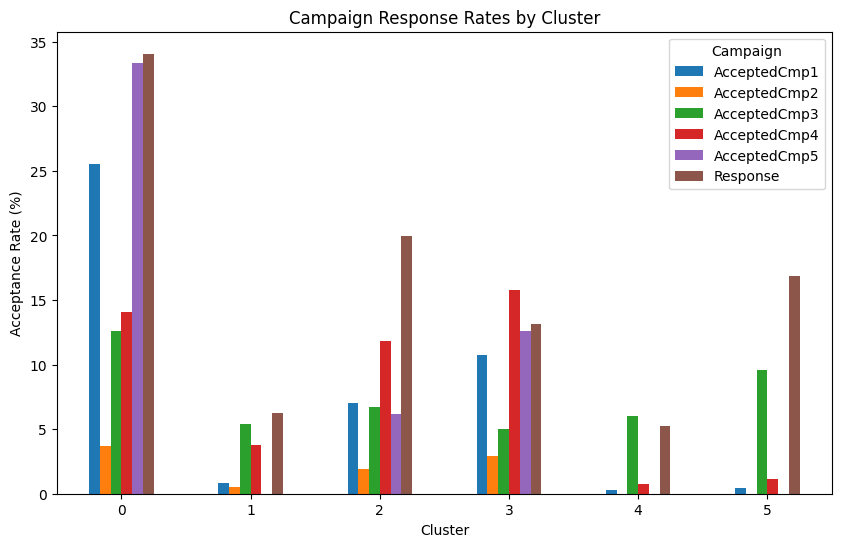

In [13]:
response_rates_pct.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Cluster")
plt.ylabel("Acceptance Rate (%)")
plt.title("Campaign Response Rates by Cluster")
plt.xticks(rotation=0)
plt.legend(title="Campaign")
plt.show()

## 3. Previous Campaign Engagement

The total number of previously accepted campaigns is calculated for each customer using AcceptedCmp1 to AcceptedCmp5. The most recent campaign response is considered separately.

In [14]:
previous_campaigns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5"
]

df["TotalAcceptedCampaigns"] = df[previous_campaigns].sum(axis=1)

In [15]:
df.groupby("Cluster")["TotalAcceptedCampaigns"].mean().round(2)

Cluster
0    0.89
1    0.11
2    0.34
3    0.47
4    0.07
5    0.11
Name: TotalAcceptedCampaigns, dtype: float64

In [16]:
previous_acceptance = df.groupby("Cluster")["TotalAcceptedCampaigns"].mean()

previous_acceptance

Cluster
0    0.892593
1    0.105691
2    0.336927
3    0.469816
4    0.070681
5    0.111617
Name: TotalAcceptedCampaigns, dtype: float64

## 4. Latest Campaign Response

The response to the most recent campaign is compared across clusters and considered alongside previous campaign engagement.

In [17]:
latest_response = df.groupby("Cluster")["Response"].mean() * 100

latest_response.round(1)

Cluster
0    34.1
1     6.2
2    19.9
3    13.1
4     5.2
5    16.9
Name: Response, dtype: float64

### Interpretation

Campaign responsiveness differs considerably across the clusters. Cluster 0 shows the strongest overall engagement, with both the highest previous campaign acceptance and the highest response to the latest campaign. Clusters 1 and 4 show consistently low engagement, while Cluster 5 stands out for its relatively high latest response despite low previous campaign acceptance. This suggests that previous and current campaign responsiveness do not follow exactly the same pattern across clusters.

## 5. Cluster Sizes

The number of customers in each cluster is checked to ensure that the campaign response rates are not based on very small customer groups.

In [12]:
df["Cluster"].value_counts().sort_index()

Cluster
0    270
1    369
2    371
3    381
4    382
5    439
Name: count, dtype: int64

The cluster sizes are sufficiently large for comparing campaign response patterns across the identified customer segments.

## 6. Final interpretation in context of customer segments


To interpret campaign responsiveness in the context of customer behaviour, the campaign results are compared with the customer profiles identified in the cluster analysis.

Cluster 0 (Young Premium Customers) combines high income and spending with strong campaign responsiveness, making it both a high-value and highly engaged segment. Cluster 2 (Established High-Value Recent Customers) similarly combines high customer value and recent purchasing activity with relatively strong campaign responsiveness.

Cluster 3 (Older High-Value Less Recent Customers) shows relatively strong historical campaign engagement but weaker response to the latest campaign. Together with its less recent purchasing activity, this may indicate potential for re-engagement.

Clusters 1 (Older Family Budget Customers) and 4 (Young Low-Value Inactive Customers) combine lower customer value with weak campaign responsiveness, consistent with their lower purchasing activity.

Cluster 5 (Young Low-Value Recent Customers) is the main exception to the broader pattern. Despite low historical campaign acceptance and relatively low customer value, it shows comparatively strong responsiveness to the latest campaign.

Overall, campaign responsiveness broadly corresponds to the differences in customer value identified by the cluster analysis, while Cluster 5 shows that recent campaign engagement does not necessarily depend on historically high customer value.
